In [ ]:
from dfft.utils.files import get_path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import re
import json

In [2]:
def extract_time(d):
    m = re.match(r"(\d{8}_\d{6})", os.path.basename(d))
    return m.group(1) if m else ""

def get_lastest_exp(base_dir):
    exp_dirs = [os.path.join(base_dir, d) for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]
    exp_dirs = sorted(exp_dirs, key=extract_time, reverse=True)
    return exp_dirs[-1]

In [3]:
names = ['moment-small', 'moment-base', 'moment-large']
configs=["-finetuned", "-lora"]
losses = ["", "-decision"]
models = [ name + c + l for name in names for c in configs for l in losses]
models.append('moment-small-zeroshot')
models.append('moment-base-zeroshot')
models.append('moment-large-zeroshot')

In [ ]:
#Create a table of regret, mse by model and data split
all = []
for model in models:
    base_dir = get_path(f"results\\experiments\\{model}\\NEMA")
    exp_dir = get_lastest_exp(base_dir)
    df = pd.read_parquet(exp_dir + "/results.parquet")
    #Compute regret
    result = df.groupby('split')[['true_profit', 'real_profit']].sum()
    result['model'] = model
    result['regret'] = (result['true_profit'] - result['real_profit']) / result['true_profit']
    result['regret'] = (result['regret'] * 100).round(1)
    all.append(result.reset_index())

regret = pd.concat(all, axis= 0)
#Reshape data
regret = regret[['model', 'split', 'regret']]
regret = regret.pivot(index='model', columns='split', values='regret')
regret = regret.sort_values('model')
print(regret)

split                             test  train    val
model                                               
moment-base-finetuned             49.7   28.9   54.8
moment-base-finetuned-decision    48.8   38.7   50.2
moment-base-lora                  49.7   28.8   54.4
moment-base-lora-decision         48.8   42.5   50.6
moment-base-zeroshot             118.2  114.7  121.5
moment-large-finetuned            49.3   28.8   55.2
moment-large-finetuned-decision   50.0   40.8   51.4
moment-large-lora                 48.3   29.3   53.9
moment-large-lora-decision        49.6   39.3   51.4
moment-large-zeroshot             95.3   96.7   97.8
moment-small-finetuned            48.6   31.5   52.4
moment-small-finetuned-decision   49.7   40.1   50.6
moment-small-lora                 48.1   32.2   52.1
moment-small-lora-decision        49.6   43.3   50.3
moment-small-zeroshot            104.0  101.7  105.3


In [5]:
all=[]
for model in models:
    base_dir = get_path(f"results\\experiments\\{model}\\NEMA")
    exp_dir = get_lastest_exp(base_dir)
    with open(exp_dir + "/results.json", 'r') as f:
            data = json.load(f)
    df = pd.DataFrame([model], columns=["model"])
    df["test_mse"] = data['test_results']['mse']
    df["val_mse"] = data['final_val_results']['mse']
    df["train_mse"] = data['final_train_results']['mse']
    all.append(df)

mse  = pd.concat(all, axis= 0)
print(mse)

                             model     test_mse      val_mse    train_mse
0           moment-small-finetuned  1425.428833  1228.364014   957.241272
0  moment-small-finetuned-decision  2459.853760  1679.445801  2157.851074
0                moment-small-lora  1426.075806  1227.158936   982.956726
0       moment-small-lora-decision  2521.183105  1719.716431  2240.185791
0            moment-base-finetuned  1449.115356  1229.195068   923.970520
0   moment-base-finetuned-decision  2356.553955  1628.137573  2105.221680
0                 moment-base-lora  1451.318970  1229.216675   910.887207
0        moment-base-lora-decision  2809.929688  1872.331787  2566.955322
0           moment-large-finetuned  1409.101318  1242.135376   933.712585
0  moment-large-finetuned-decision  2250.712891  1617.128174  2015.442627
0                moment-large-lora  1406.375366  1240.238037   953.742920
0       moment-large-lora-decision  2253.629883  1615.110596  2008.418701
0            moment-small-zeroshot  21

In [20]:
metrics = pd.merge(mse, regret, on='model', how='inner')
print(metrics.sort_values('model'))

                              model     test_mse      val_mse    train_mse  \
4             moment-base-finetuned  1449.115356  1229.195068   923.970520   
5    moment-base-finetuned-decision  2356.553955  1628.137573  2105.221680   
6                  moment-base-lora  1451.318970  1229.216675   910.887207   
7         moment-base-lora-decision  2809.929688  1872.331787  2566.955322   
13             moment-base-zeroshot  2153.526855  1523.163330  1962.787231   
8            moment-large-finetuned  1409.101318  1242.135376   933.712585   
9   moment-large-finetuned-decision  2250.712891  1617.128174  2015.442627   
10                moment-large-lora  1406.375366  1240.238037   953.742920   
11       moment-large-lora-decision  2253.629883  1615.110596  2008.418701   
14            moment-large-zeroshot  2087.747070  1483.763428  1918.667480   
0            moment-small-finetuned  1425.428833  1228.364014   957.241272   
1   moment-small-finetuned-decision  2459.853760  1679.445801  2

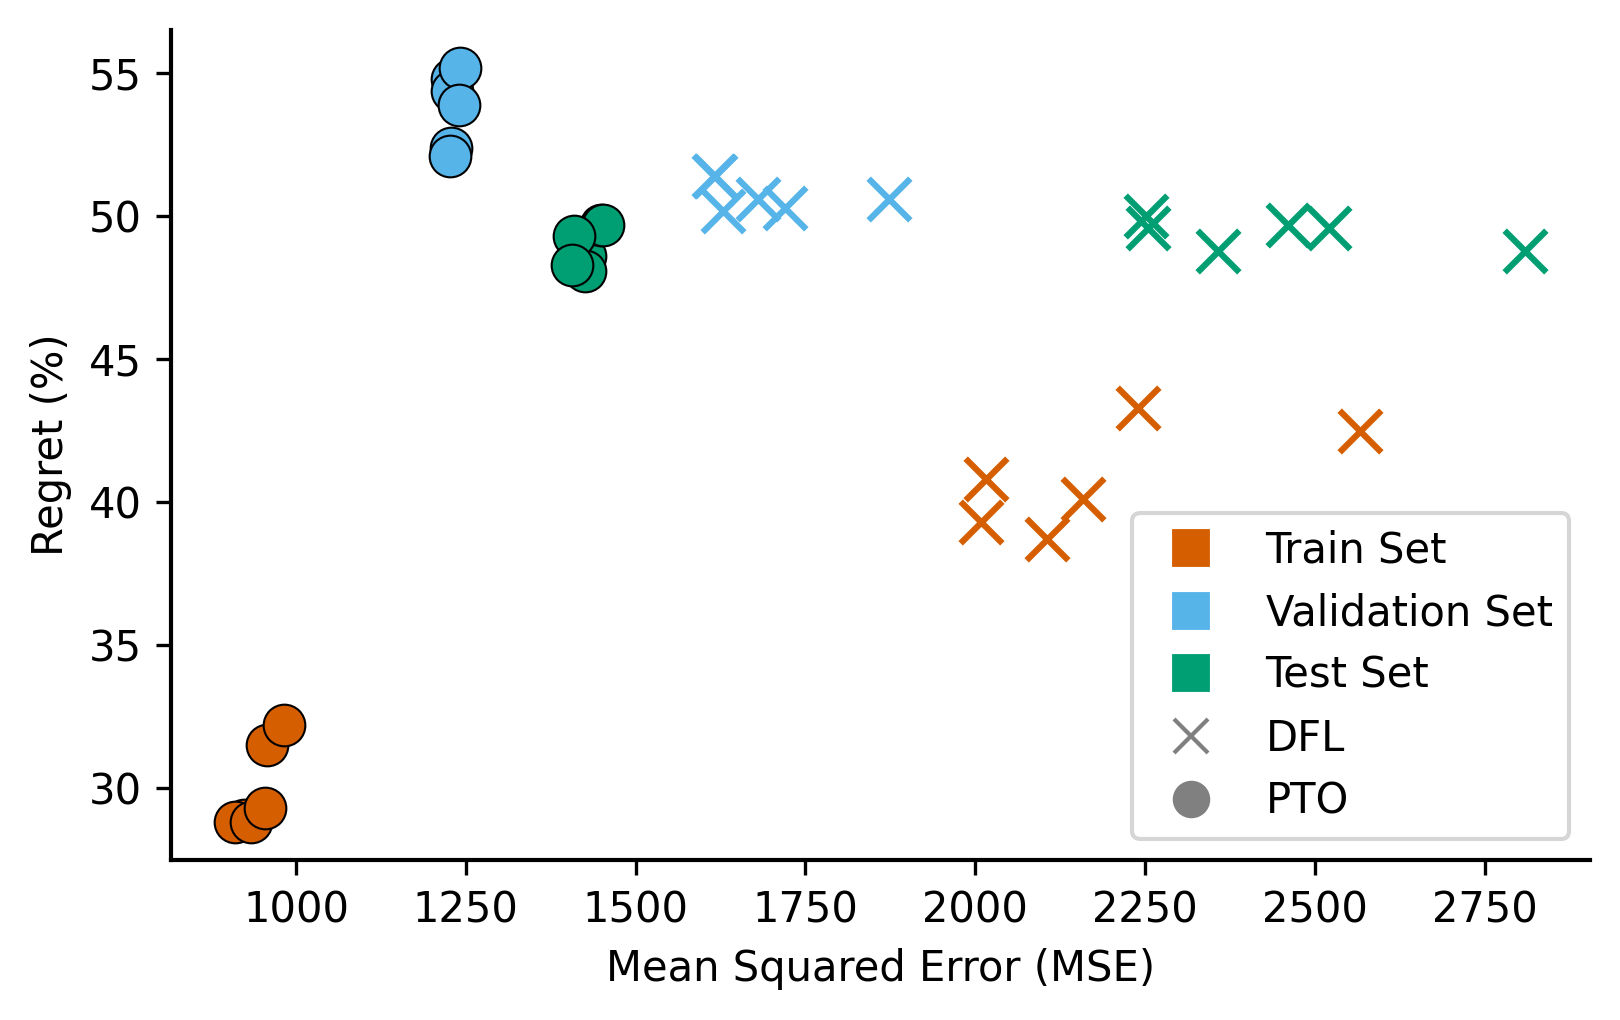

In [81]:
#Create a scatter plot of Regret vs. MSE
dfl = metrics.loc[metrics['model'].str.contains('decision')]
pto = metrics.loc[(~metrics['model'].str.contains('decision')) & (~metrics['model'].str.contains('zeroshot'))]

plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

ax.scatter(dfl["train_mse"], dfl["train"], color='#D55E00', marker='x', s=100, label='Train (dfl)')
ax.scatter(dfl["val_mse"], dfl["val"], color='#56B4E9', marker='x', s=100, label='Val (dfl)')
ax.scatter(dfl["test_mse"], dfl["test"], color='#009E73', marker='x', s=100, label='Test (dfl)')
ax.scatter(pto["train_mse"], pto["train"], color='#D55E00', marker='o', s=100, edgecolors='k', linewidth=0.5, label='Train (pto)')
ax.scatter(pto["val_mse"], pto["val"], color='#56B4E9', marker='o', s=100, edgecolors='k', linewidth=0.5, label='Val (pto)')
ax.scatter(pto["test_mse"], pto["test"], color='#009E73', marker='o', s=100, edgecolors='k', linewidth=0.5, label='Test (pto)')

ax.set_xlabel('Mean Squared Error (MSE)', fontsize=10)
ax.set_ylabel('Regret (%)', fontsize=10)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='Train Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='Validation Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#009E73', markersize=10, label='Test Set'),
    # Marker indicators
    Line2D([0], [0], color='gray', marker='x', linestyle='None', markersize=8, label='DFL'),
    Line2D([0], [0], color='gray', marker='o', linestyle='None', markersize=8, label='PTO')
]


ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(handles=legend_elements, loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig("plots/regret_vs_mse.pdf", format='pdf', bbox_inches='tight') 
plt.show()

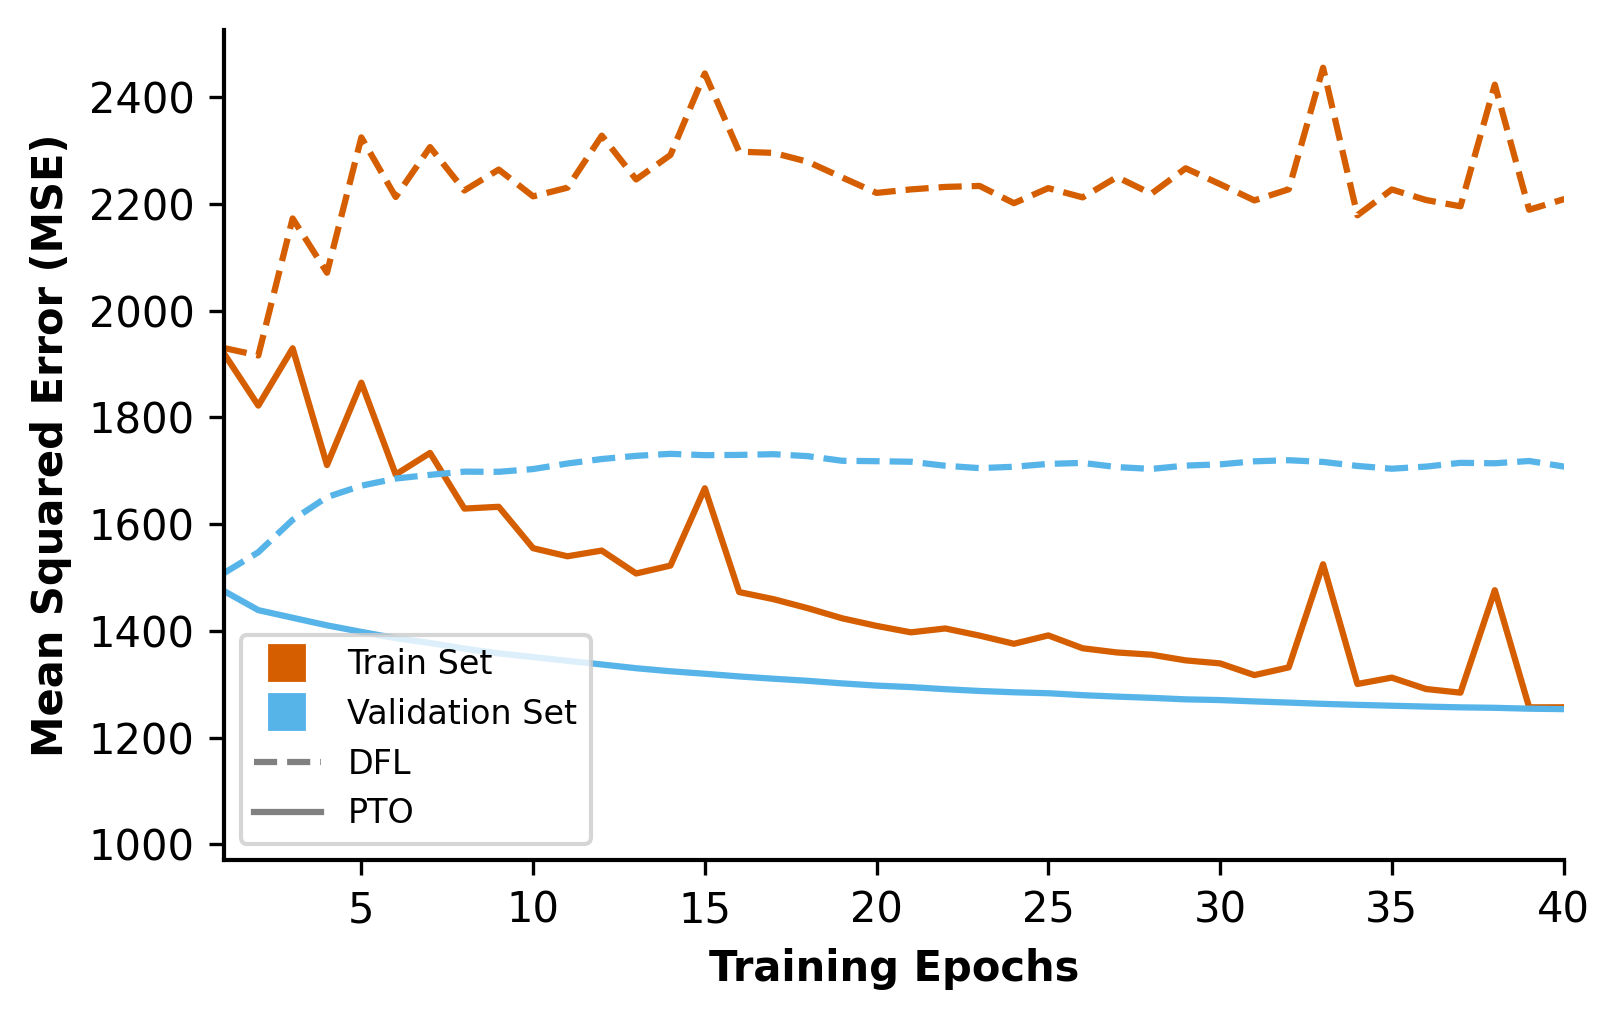

In [93]:
#Plot trajectories for moment-small-lora


#Read training data

#moment-small-lora
base_dir = get_path(f"results\\experiments\\moment-small-lora\\NEMA")
exp_dir = get_lastest_exp(base_dir)
with open(exp_dir + "/results.json", 'r') as f:
        pto = json.load(f)

#moment-small-lora-decision
base_dir = get_path(f"results\\experiments\\moment-small-lora-decision\\NEMA")
exp_dir = get_lastest_exp(base_dir)
with open(exp_dir + "/results.json", 'r') as f:
        dfl = json.load(f)
dfl["training_history"]["train"]["mse"]

#Generate plot
plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

#Training
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["train"]["mse"],
        linestyle= "--",
        color = '#D55E00'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["train"]["mse"],
        linestyle= "-",
        color = '#D55E00'
)

#Validation
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["val"]["mse"],
        linestyle= "--",
        color = '#56B4E9'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["val"]["mse"],
        linestyle= "-",
        color = '#56B4E9'
)


ax.set_xlabel('Training Epochs', fontweight='bold', fontsize=10)
ax.set_ylabel('Mean Squared Error (MSE)', fontweight='bold', fontsize=10)

ax.set_xlim(xmin=1, xmax=40)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='Train Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='Validation Set'),
    # Marker indicators
    Line2D([0], [0], color='gray', linestyle='--', label='DFL'),
    Line2D([0], [0], color='gray', linestyle='-', label='PTO')
]

ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig("plots/mse_traj.pdf", format='pdf', bbox_inches='tight') 
plt.show()

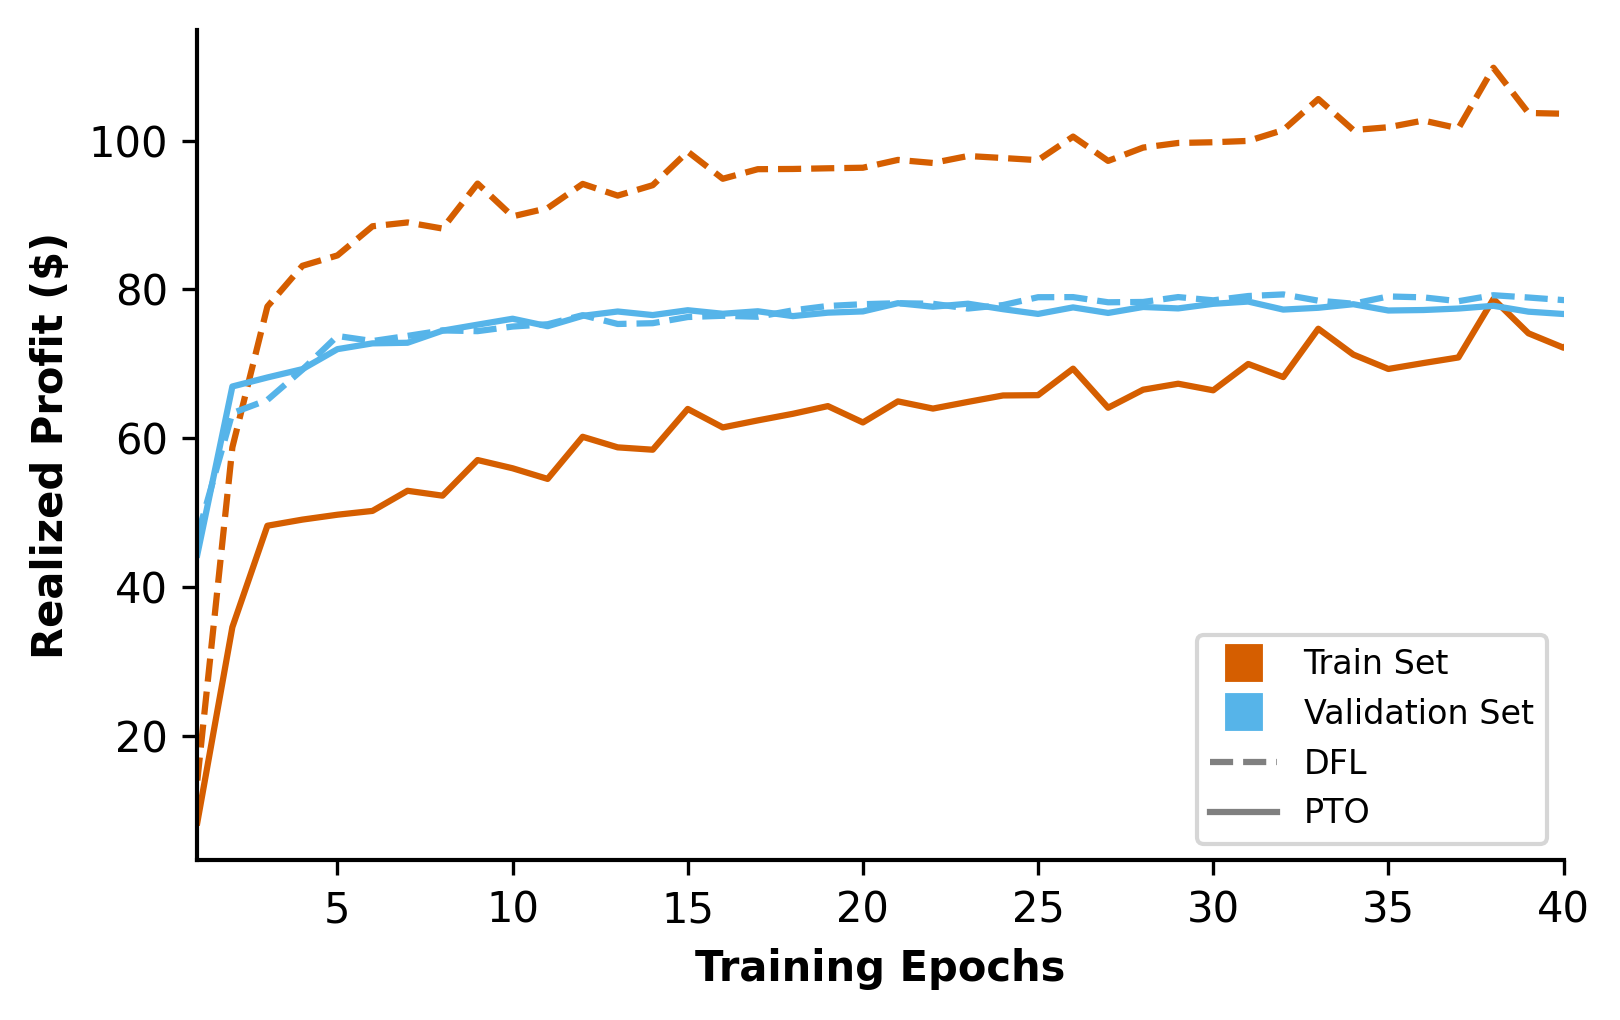

In [94]:
#Generate plot
plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

#Training
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["train"]["profit"],
        linestyle= "--",
        color = '#D55E00'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["train"]["profit"],
        linestyle= "-",
        color = '#D55E00'
)

#Validation
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["val"]["profit"],
        linestyle= "--",
        color = '#56B4E9'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["val"]["profit"],
        linestyle= "-",
        color = '#56B4E9'
)


ax.set_xlabel('Training Epochs', fontweight='bold', fontsize=10)
ax.set_ylabel('Realized Profit ($)', fontweight='bold', fontsize=10)

ax.set_xlim(xmin=1, xmax=40)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='Train Set'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='Validation Set'),
    # Marker indicators
    Line2D([0], [0], color='gray', linestyle='--', label='DFL'),
    Line2D([0], [0], color='gray', linestyle='-', label='PTO')
]

ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig("plots/profit_traj.pdf", format='pdf', bbox_inches='tight') 
plt.show()